# Subglacial drainage (GlaDS): channel discharge fraction, sheet transit time and channel network length

**Paper:** Tim Hill<sup>1</sup>, Derek Bingham<sup>2</sup>, Gwenn E. Flowers<sup>1</sup>, Matthew J. Hoffman<sup>3</sup>,
"Computationally efficient subglacial drainage modelling using Gaussian process emulators: GlaDS-GP v1.0",
*Geoscientific Model Development* 18, 4045–4074 (2025), [doi:10.5194/gmd-18-4045-2025](https://doi.org/10.5194/gmd-18-4045-2025).

<sup>1</sup> Department of Earth Sciences, Simon Fraser University, Burnaby, BC, Canada<br>
<sup>2</sup> Department of Statistics and Actuarial Science, Simon Fraser University, Burnaby, BC, Canada<br>
<sup>3</sup> Fluid Dynamics and Solid Mechanics Group, Los Alamos National Laboratory, Los Alamos, NM, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

Hill et al. ran the GlaDS subglacial drainage model 612 times on a synthetic 100 km × 25 km ice-sheet margin,
varying eight parameters (512 training runs on a Sobol' sequence, 100 test runs on a Latin hypercube), and
deposited the runs with their code. This notebook estimates active subspaces of the paper's three scalar
outputs (channel discharge fraction $f_Q$, log sheet transit time $\log_{10} T_s$, channel network length
$L_c$) from the stored training runs without gradients, using a global quadratic fit (QPHD), and checks them
with local linear gradients, an OLS direction and the 100 independent test runs. $f_Q$ and $\log_{10} T_s$
each have one dominant direction (eigenvalue ratios $\lambda_1/\lambda_2$ = 10.97 and 12.43), $L_c$ needs two
(ratios 4.9 and 4.92; the dimension is chosen by leave-one-out $R^2$), and the order of the inputs by activity score agrees with the order of the paper's
Sobol' indices (Fig. 12; rank correlations 0.97–0.99).

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ normalized inputs with density $\rho$, the matrix
$C = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x} = W \Lambda W^\top$ has eigenvalues
$\lambda_1 \ge \dots \ge \lambda_m \ge 0$ that measure the mean squared change of $f$ along the eigenvectors
$\mathbf{w}_i$. When the first $n$ eigenvalues are much larger than the rest, $f$ changes mostly along the
span of $W_1 = [\mathbf{w}_1, \dots, \mathbf{w}_n]$, and $f(\mathbf{x}) \approx g(W_1^\top \mathbf{x})$: a
plot of $f$ against the active variables $W_1^\top \mathbf{x}$ (a sufficient summary plot) shows the
structure, and a surrogate in $n$ variables can replace one in $m$. Without gradients, $C$ is estimated from
function values, here from the gradient of a least-squares quadratic fit. See P. G. Constantine,
*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM (2015),
[doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**GlaDS** (Werder et al. 2013), in its ISSM v4.24 implementation with the laminar–turbulent sheet flow of
Hill et al. (2024b) (p. 4046), couples a distributed water sheet (cavities) to a network of ice-walled
channels on the edges of a triangular mesh. The sheet equations, as printed on p. 4065:

$$-k_s h_s^3 \nabla\phi = \mathbf{q}_s + \omega Re\, \mathbf{q}_s, \qquad\qquad (A1)$$

$$\frac{\partial h_s}{\partial t} = f_b \frac{h_b - h_s}{r_b h_b} u_b - \tilde{A} h_s |N|^{n-1} N, \qquad\qquad (A2)$$

$$\frac{e_v}{\rho_w g}\frac{\partial\phi}{\partial t} + \nabla\cdot\mathbf{q}_s + f_b \frac{h_b - h_s}{r_b h_b} u_b - \tilde{A} h_s |N|^{n-1} N = m_s, \qquad\qquad (A3)$$

with $\phi$ the hydraulic potential, $h_s$ the sheet thickness, $\mathbf{q}_s$ the sheet discharge per unit
width, $Re = |\mathbf{q}_s|/\nu$, $N$ the effective pressure, $\tilde{A} = \frac{2}{n^n} A$ and $f_b$ a switch
of the sliding-opening term. The channel discharge and cross-section obey (p. 4066)

$$Q = -k_c S^{\alpha_c} |\psi_c|^{\beta_c - 2} \psi_c, \qquad \frac{\partial S}{\partial t} = \frac{\Xi - \Pi}{\rho_i L} - \tilde{A} S |N|^{n-1} N, \qquad\qquad (A4), (A6)$$

with $\psi_c = \partial\phi/\partial s$, $\alpha_c = 5/4$, $\beta_c = 3/2$, $\Xi$ the dissipation and $\Pi$ the
sensible-heat term; the sheet flow in a strip of width $l_c$ beneath each channel adds to the channel's
dissipation and sensible-heat terms (Eqs. A7–A8).

**Set-up** (pp. 4051–4052): a 100 km × 25 km synthetic land-terminating margin modified from SHMIP (flat bed at
350 m, surface 390–1910 m), 60 moulins, a mesh of 3693 nodes, a basal melt rate of 0.05 m w.e. a⁻¹ and surface
melt from a degree-day model driven by 2014 KAN_L air temperatures; each run covers 2 years with identical
forcing and the first is discarded. One run took 25 min, the 512-run ensemble 216 h (Table 4, p. 4058).

**Quantities of interest** (p. 4053), each from six fluxgates 5, 10, …, 30 km from the terminus:

- $f_Q$: channel discharge crossing a fluxgate divided by total (sheet + channel) discharge, averaged over the
  six gates (column `fQ_mean`). The text says "melt-season-integrated"; the authors' aggregation script
  (`src/aggregate_outputs.py` in the deposit) sums the discharge over all stored daily outputs of the run.
- $\log T_s$: the time a water parcel would take to reach the terminus through the sheet, in years; the stored
  values are $\log_{10} T_s$ at each gate (annual mean of $T_s$ in that script) and their mean over the six
  gates (column `log10Ts_mean`). The text says that $T_s$ "is computed as the average time starting from each
  of the same six fluxgate positions" (p. 4053); the stored column is the mean of the six $\log_{10}$ values
  (check below), i.e. $\log_{10}$ of the geometric mean of the six times, not the log of their average. Table 5
  writes "log $T_s$" without a base; its test range is that of the stored column (check below).
- $L_c$: total length of all channel segments with radius $R \ge 0.5$ m (column `Lc_R0.5m`), the maximum over
  the year in that script, in km. It is a sum over mesh edges, so it can exceed the 100 km domain length
  (Table 5's test range is [16, 1581] km). Table 1 gives the unit as m; Table 5 and Fig. 12 use km, as stored.
  The text calls the threshold "R = h_b = 0.5 m, corresponding to the maximum bed bump height", but Table 2's
  range of $h_b$ reaches 1 m.

The deposit also stores each $f_Q$ and $\log_{10} T_s$ gate and $L_c$ for $R \ge 1$ m; they are in the data
files, and the notebook uses the 30 km gates only in the comparison with Fig. 12.

**Inputs** (Table 2, p. 4047; column order of the authors' design files, in which $l_c$ precedes $A$):

| # | name | symbol | description | range | units (as printed) |
|---|---|---|---|---|---|
| 1 | `k_s` | $k_s$ | sheet conductivity | [0.01, 1] | Pa s⁻¹ |
| 2 | `k_c` | $k_c$ | channel conductivity | [0.05, 0.5] | m^3/2 s⁻¹ |
| 3 | `h_b` | $h_b$ | bed bump height | [0.05, 1] | m |
| 4 | `r_b` | $r_b$ | bed bump aspect ratio | [10, 100] | – |
| 5 | `l_c` | $l_c$ | width of sheet beneath channels | [1, 100] | m |
| 6 | `A` | $A$ | ice flow law coefficient | [1e-24, 1e-23] | s⁻¹ Pa⁻³ |
| 7 | `omega` | $\omega$ | laminar–turbulent transition parameter | [1/5000, 1/500] | – |
| 8 | `e_v` | $e_v$ | englacial void fraction | [5e-5, 5e-4] | – |

The units of $k_s$ and $k_c$ are given as printed; Eqs. (A1) and (A4) imply Pa⁻¹ s⁻¹ and m^3/2 kg^-1/2 (this
notebook's dimensional reading, not stated in the paper). The paper applies "a log transformation to all GlaDS
parameters" (p. 4052).

**Design** (p. 4052): training runs at 512 points of a Sobol' sequence, test runs at 100 points of a
centred-discrepancy-minimised Latin hypercube; no run was filtered out. The generator of the training design is
set in the authors' `experiments/synthetic/train_config.py` (in the deposit): `scipy.stats.qmc.Sobol` in eight
dimensions with `seed=20240318` (scrambled, scipy's default), mapped affinely onto the $\log_{10}$ bounds of
Table 2; the check below reproduces the stored design from it. The paper says that its scalar emulators use
$m$ = 256 training simulations (p. 4058). That these are the first 256 rows, and that the Sobol' indices of
Fig. 12 come from these emulators, is from the authors' code (`train_config.py` sets `m = 256`;
`experiments/synthetic/analysis/sensitivity_indices.py` reads rows `[:config.m]`). Here all 512 training runs
estimate the subspaces and choose their dimension (by leave-one-out $R^2$); the 100 test runs are used only as
an independent check.

**Input density and scaling (this notebook's choice).** The checks below show that both designs are uniform in
$\log_{10}$ of each input over the Table 2 range, so the density is log-uniform on each input, independent.
Each input is mapped through its CDF, i.e. $\log_{10} x$ affinely onto $[-1, 1]$ (`ac.Uniform` on the log10
bounds). Eigenvector weights refer to these normalized log inputs.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import scipy
import matplotlib.pyplot as plt
import active_subspaces as ac
from scipy.stats import qmc, spearmanr

SEED = 637                       # the only seed of this notebook's own randomness (bootstrap)
AUTHORS_SOBOL_SEED = 20240318    # seed of the authors' training design (train_config.py); only to reproduce it
t_start = time.perf_counter()
NBOOT = 500
warnings.filterwarnings("ignore", category=ac.ValidityWarning)  # QPHD on a uniform space: see text
np.set_printoptions(precision=4, suppress=False)

## Load the data

`glads_{train,test}_inputs.csv` hold `run_id` and the eight inputs in physical units; `glads_{train,test}_qoi.csv`
hold `run_id` and 16 outputs per run (row $i$ of each file is the same run).

In [2]:
Xtr = np.loadtxt("glads_train_inputs.csv", delimiter=",")
Ytr = np.loadtxt("glads_train_qoi.csv", delimiter=",")
Xte = np.loadtxt("glads_test_inputs.csv", delimiter=",")
Yte = np.loadtxt("glads_test_qoi.csv", delimiter=",")
with open("glads_train_qoi.csv") as fh:
    fh.readline()
    QCOLS = [c.split(" [")[0] for c in fh.readline().lstrip("# ").strip().split(",")]
NAMES = ["k_s", "k_c", "h_b", "r_b", "l_c", "A", "omega", "e_v"]
lower = np.array([0.01, 0.05, 0.05, 10.0, 1.0, 1e-24, 1 / 5000, 5e-5])  # Table 2, p. 4047
upper = np.array([1.0, 0.5, 1.0, 100.0, 100.0, 1e-23, 1 / 500, 5e-4])
Ltr, Lte = np.log10(Xtr[:, 1:]), np.log10(Xte[:, 1:])  # the uniform variables are log10 of the inputs
space = ac.Uniform(np.log10(lower), np.log10(upper), names=["log10 " + n for n in NAMES])
col = {c: i for i, c in enumerate(QCOLS)}
QOI = {"fQ": "fQ_mean", "log10 Ts": "log10Ts_mean", "Lc": "Lc_R0.5m"}
print("train inputs", Xtr.shape, "train QoIs", Ytr.shape, "test inputs", Xte.shape, "test QoIs", Yte.shape)
print("QoI columns:", QCOLS[1:])

train inputs (512, 9) train QoIs (512, 17) test inputs (100, 9) test QoIs (100, 17)
QoI columns: ['fQ_x05km', 'fQ_x10km', 'fQ_x15km', 'fQ_x20km', 'fQ_x25km', 'fQ_x30km', 'fQ_mean', 'log10Ts_x05km', 'log10Ts_x10km', 'log10Ts_x15km', 'log10Ts_x20km', 'log10Ts_x25km', 'log10Ts_x30km', 'log10Ts_mean', 'Lc_R0.5m', 'Lc_R1.0m']


In [3]:
def unit(L):
    return (L - np.log10(lower)) / (np.log10(upper) - np.log10(lower))
Utr, Ute = unit(Ltr), unit(Lte)
print("train: normalized range", Utr.min().round(5), Utr.max().round(5))
for k in (256, 512):
    occ = [len(np.unique(np.floor(Utr[:k, j] * k))) for j in range(8)]
    print(f"first {k} Sobol' points: occupied 1/{k} strata per input", occ)
cells = np.round(Ute * 100 - 0.5, 4)
print("test: max |u*100 - 0.5 - integer| =", f"{np.max(np.abs(cells - np.round(cells))):.1e}",
      "; strata per input", [len(np.unique(np.round(cells[:, j]))) for j in range(8)])
# the authors' training design (train_config.py): scrambled Sobol' on the log10 bounds listed there
# (omega's bounds are listed high-to-low, which reverses the direction of that coordinate, not its range)
b_lo = np.log10([0.01, 0.05, 0.05, 10.0, 1.0, 1e-24, 1 / 500, 5e-5])
b_hi = np.log10([1.0, 0.5, 1.0, 100.0, 100.0, 1e-23, 1 / 5000, 5e-4])
try:
    Lsob = b_lo + qmc.Sobol(8, seed=AUTHORS_SOBOL_SEED, optimization=None).random(512) * (b_hi - b_lo)
    print(f"scrambled Sobol' (scipy {scipy.__version__}, seed={AUTHORS_SOBOL_SEED}) vs log10 of the training "
          f"design: max |difference| {np.max(np.abs(Lsob - Ltr)):.1e}")
except TypeError:
    print(f"this scipy ({scipy.__version__}) no longer accepts the seed= argument of the authors' design")
TABLE_B1 = {  # Table B1, p. 4067, as printed: test simulations 66, 63 and 71 (numbered from 0)
    66: [0.37, 0.31, 0.064, 75, 1.3, 2.1e-24, 1.2e-3, 1.2e-4],
    63: [0.12, 0.059, 0.063, 39, 28, 2.9e-24, 1.3e-4, 1.3e-4],
    71: [0.031, 0.16, 0.36, 25, 41, 1.2e-24, 1.4e-3, 2.7e-4],
}
print("Table B1 (run_id = simulation + 1):")
n_same = 0
for sim, vals in TABLE_B1.items():
    row = Xte[Xte[:, 0] == sim + 1, 1:][0]
    same = [float(f"{a:.2g}") == b for a, b in zip(row, vals)]
    n_same += sum(same)
    d5 = np.max(np.abs(Lte[:, :5] - np.log10(vals[:5])), axis=1)  # largest |log10 difference|, first 5 inputs
    o = np.argsort(d5)
    print(f"  simulation {sim}: file", " ".join(f"{v:.2g}" for v in row),
          f"| differs in {[NAMES[i] for i in range(8) if not same[i]]}"
          f" | first five inputs: run_id {int(Xte[o[0], 0])} within {d5[o[0]]:.3f} decades,"
          f" next run_id {int(Xte[o[1], 0])} at {d5[o[1]]:.2f}")
print(f"  {n_same} of 24 printed values agree to two digits; Table B1's omega 1.3e-4 (simulation 63) lies in "
      f"Table 2's range [{lower[6]:.1e}, {upper[6]:.1e}]: {bool(lower[6] <= 1.3e-4 <= upper[6])}")
for name, Y in (("train", Ytr), ("test", Yte)):
    dfq = np.max(np.abs(Y[:, 1:7].mean(1) - Y[:, col["fQ_mean"]]) / np.abs(Y[:, 1:7]).mean(1))
    dts = np.max(np.abs(Y[:, 8:14].mean(1) - Y[:, col["log10Ts_mean"]]) / np.abs(Y[:, 8:14]).mean(1))
    print(f"{name}: mean columns vs mean of the 6 gates, max relative deviation fQ {dfq:.1e}, log10 Ts {dts:.1e}")
    dav = np.max(np.abs(np.log10(np.mean(10 ** Y[:, 8:14], axis=1)) - Y[:, col["log10Ts_mean"]]))
    print(f"{name}: log10 of the average of the six T_s differs from log10Ts_mean by up to {dav:.3f}")
    print(f"{name}: fQ in [{Y[:, 1:8].min():.3g}, {Y[:, 1:8].max():.4g}]; "
          f"Lc(R>=1 m) <= Lc(R>=0.5 m) in {np.sum(Y[:, 16] <= Y[:, 15])} of {len(Y)} runs; "
          f"runs with Lc(R>=0.5 m) = 0: {np.sum(Y[:, 15] == 0)}")
for q, c in QOI.items():
    v = Yte[:, col[c]]
    print(f"test range {q}: [{v.min():.4g}, {v.max():.4g}]")

train: normalized range 1e-05 0.99995
first 256 Sobol' points: occupied 1/256 strata per input [256, 256, 256, 256, 256, 256, 256, 256]
first 512 Sobol' points: occupied 1/512 strata per input [512, 512, 512, 512, 512, 512, 512, 512]
test: max |u*100 - 0.5 - integer| = 0.0e+00 ; strata per input [100, 100, 100, 100, 100, 100, 100, 100]
scrambled Sobol' (scipy 1.18.1, seed=20240318) vs log10 of the training design: max |difference| 2.1e-07
Table B1 (run_id = simulation + 1):
  simulation 66: file 0.37 0.31 0.064 75 1.3 2.1e-24 0.0012 0.00012 | differs in [] | first five inputs: run_id 67 within 0.004 decades, next run_id 91 at 0.28
  simulation 63: file 0.12 0.059 0.063 39 28 2.9e-24 0.0013 0.00013 | differs in ['omega'] | first five inputs: run_id 64 within 0.011 decades, next run_id 63 at 0.27
  simulation 71: file 0.031 0.16 0.36 25 41 1.2e-24 0.0014 0.00027 | differs in [] | first five inputs: run_id 72 within 0.010 decades, next run_id 25 at 0.28
  23 of 24 printed values agree to 

Checks of the files against the paper (printed above). Every $\log_{10}$ input of the first 256 and of all 512
training points fills all 256 and all 512 equal strata of its range, as the first $2^k$ points of a Sobol'
sequence do in log space, and the authors' generator (scipy's scrambled Sobol' with their seed, mapped onto
their bounds) reproduces the $\log_{10}$ design to 2.1e-07, the 7-digit print of the design files. Each test
input sits at the centres of 100 strata, a centred Latin hypercube.

Table B1 (p. 4067) lists the parameters of test simulations 66, 63 and 71; they are the rows with run_id 67, 64
and 72 (the paper numbers runs from 0). 23 of the 24 printed values agree with the file to two digits, and in the
first five inputs each of the three runs lies within 0.011 decades of its Table B1 column, while the next closest
test run is at least 0.27 decades away. The exception is $\omega$ of simulation 63: Table B1 prints
$1.3 \times 10^{-4}$, which lies outside the Table 2 range $[1/5000, 1/500] = [2 \times 10^{-4}, 2 \times 10^{-3}]$
(p. 4047), while the file has $1.3 \times 10^{-3}$. The printed value is presumably a misprint for
$1.3 \times 10^{-3}$.

The mean columns equal the mean of the six gates to a relative 1.8e-07 or better (float32 storage). For
$\log_{10} T_s$ this is the mean of the six logs: $\log_{10}$ of the average of the six times would differ from
the stored column by up to 0.121 (training runs) and 0.054 (test runs). The test ranges, [0.0015, 0.9901],
[-1.279, 1.669] and [15.85, 1581], match Table 5 (p. 4059): [0.0015, 0.99], [−1.28, 1.67] and [16, 1581] km.
One training run has no channel with $R \ge 0.5$ m ($L_c = 0$); it is kept, like every other run.

## Estimate the active subspaces

There are no gradients: GlaDS returns none, and finite differences would cost $m + 1 = 9$ runs of about 25 min
(Table 4) per gradient. With $M = 512$ training runs and $(m+1)(m+2)/2 = 45$ coefficients of a quadratic in $m = 8$ inputs,
the global quadratic estimator **QPHD** is the primary estimator. It fits
$q(\mathbf{x}) = c + \mathbf{g}^\top\mathbf{x} + \tfrac12 \mathbf{x}^\top H \mathbf{x}$ by least squares in the
normalized inputs and returns $\hat C = \mathbf{g}\mathbf{g}^\top + H \Sigma H$ with $\Sigma = I/3$, the
covariance of the uniform density on $[-1, 1]^8$. On this density $\hat C$ is exactly
$\mathbb{E}[\nabla q\, \nabla q^\top]$, the active-subspace matrix of the fitted quadratic. (The library warns
that QPHD estimates the matrix of $f$ itself only for Gaussian inputs; that warning is silenced, and the
subspace is read as that of the quadratic fit, whose leave-one-out and test $R^2$ are printed below.)

Two checks that do not depend on the quadratic: **local linear gradients** (a linear fit to the 13 nearest
training points of each run, the library default for $m = 8$) fed to the gradient-based estimator, and the
**OLS** direction (the normalized gradient of a global linear fit; one direction only). Eigenvector signs are
set by `ac.orient(by="covariance")`: $f$ increases with each $\mathbf{w}_i^\top \mathbf{x}$; the paper has no
active-subspace figure to match. The bootstrap resamples the 512 runs `NBOOT` = 500 times with seed `SEED`.

In [4]:
def fit_all(c, n=None, nboot=NBOOT):
    f = Ytr[:, col[c]]
    q = ac.active_subspace(space=space, X=Ltr, f=f, estimator="qphd", n=n, nboot=nboot, rng=SEED, qoi=c)
    q = ac.orient(q, by="covariance", X=Ltr, f=f, columns=space.dim)
    ll = ac.active_subspace(space=space, grads=ac.local_linear_gradients(X=Ltr, f=f, space=space),
                            n=n, nboot=nboot, rng=SEED, qoi=c)
    ll = ac.orient(ll, by="reference", reference=q, columns=space.dim)
    ols = ac.active_subspace(space=space, X=Ltr, f=f, estimator="ols", n=1, qoi=c)
    ols = ac.orient(ols, by="reference", reference=q, columns=1)
    return q, ll, ols

def dist(A, B):
    """Distance between the column spans of A and B: ||A A^T - B B^T||_2."""
    return np.linalg.norm(A @ A.T - B @ B.T, 2)

R = {q: fit_all(c) for q, c in QOI.items()}
for q, (qp, ll, ols) in R.items():
    lam = np.abs(qp.eigenvalues)
    lo, hi = ac.bootstrap_interval(np.abs(qp.bootstrap_eigenvalues))
    print(f"--- {q}: QPHD eigenvalues (95% bootstrap interval)")
    for k in range(4):
        print(f"  lambda_{k + 1} = {lam[k]:.4g}  [{lo[k]:.4g}, {hi[k]:.4g}]")
    print("  ratios lambda_k/lambda_k+1, k = 1..4:", np.round(lam[:4] / lam[1:5], 2))
    print("  share of the trace left out by n = 1, 2, 3:", np.round(1 - np.cumsum(lam)[:3] / lam.sum(), 3))
    print("  mean bootstrap subspace distance, k = 1..5:",
          np.round(qp.bootstrap_distances.mean(0)[:5], 3))
    lll = np.abs(ll.eigenvalues)
    print("  local-linear ratios k = 1..4:", np.round(lll[:4] / lll[1:5], 2))
    print(f"  distance QPHD vs local linear: n=1 {dist(qp.W[:, :1], ll.W[:, :1]):.3f}, "
          f"n=2 {dist(qp.W[:, :2], ll.W[:, :2]):.3f}; QPHD w1 vs OLS: {dist(qp.W[:, :1], ols.W[:, :1]):.3f}")

--- fQ: QPHD eigenvalues (95% bootstrap interval)
  lambda_1 = 0.2922  [0.2747, 0.3238]
  lambda_2 = 0.02663  [0.01949, 0.03655]
  lambda_3 = 0.004517  [0.002691, 0.009696]
  lambda_4 = 0.001262  [0.001253, 0.003922]
  ratios lambda_k/lambda_k+1, k = 1..4: [10.97  5.9   3.58  1.16]
  share of the trace left out by n = 1, 2, 3: [0.105 0.023 0.009]
  mean bootstrap subspace distance, k = 1..5: [0.033 0.12  0.369 0.733 0.712]
  local-linear ratios k = 1..4: [18.19  1.63  1.32  1.26]
  distance QPHD vs local linear: n=1 0.031, n=2 0.119; QPHD w1 vs OLS: 0.010
--- log10 Ts: QPHD eigenvalues (95% bootstrap interval)
  lambda_1 = 0.9567  [0.8781, 1.068]
  lambda_2 = 0.07695  [0.06095, 0.1042]
  lambda_3 = 0.01606  [0.01201, 0.02509]
  lambda_4 = 0.004495  [0.003544, 0.01364]
  ratios lambda_k/lambda_k+1, k = 1..4: [12.43  4.79  3.57  1.84]
  share of the trace left out by n = 1, 2, 3: [0.098 0.026 0.01 ]
  mean bootstrap subspace distance, k = 1..5: [0.04  0.128 0.286 0.662 0.786]
  local-lin

For $f_Q$, $\lambda_1/\lambda_2$ = 10.97 and the next ratios are 5.9, 3.58 and 1.16; leaving out all but $\mathbf{w}_1$
drops 0.105 of the trace, and the bootstrap subspace distance of $\mathbf{w}_1$ is 0.033. For $\log_{10} T_s$ the
ratios are 12.43, 4.79, 3.57 (0.098 of the trace outside $\mathbf{w}_1$, distance 0.04). For $L_c$ the first two
ratios are 4.9 and 4.92 (0.212 of the trace outside $\mathbf{w}_1$, 0.051 outside the first two; distances 0.044
and 0.101).

The checks agree on the first direction: the distance between the QPHD and local-linear $\mathbf{w}_1$ is 0.031,
0.062 and 0.042, and between QPHD $\mathbf{w}_1$ and the OLS direction 0.010, 0.084 and 0.017. The local-linear
$\lambda_1/\lambda_2$ (18.19, 12.51, 4.81) also show one dominant direction, but after it their ratios are 1.63,
1.5 and 2.46 and then near 1: gradients from 13-point local fits in eight dimensions carry noise of a similar size
in every direction, which fills the trailing eigenvalues. They confirm $\mathbf{w}_1$, not the gaps after it;
those come from the quadratic fit.

### Choice of dimension

A radial-basis surrogate on $n$ active variables (the library's RBF with its leave-one-out length-scale search),
fitted to the 512 training runs, shows what each added direction buys. One rule, this notebook's choice, sets the
dimension of all three outputs from the training runs alone: start at n = 1 and add an active variable while it
raises the leave-one-out (LOO) $R^2$ by at least 0.05. The $R^2$ on the 100 test runs is printed as a confirmation
and does not enter the choice.

In [5]:
def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)

DIMTAB = {}
for q, c in QOI.items():
    f, ft = Ytr[:, col[c]], Yte[:, col[c]]
    print(f"--- {q}: RBF surrogate on n active variables (QPHD subspace)")
    for n in (1, 2, 3):
        sub = ac.with_dimension(R[q][0], n=n)
        s = ac.fit_surrogate(X=Ltr, f=f, subspace=sub, kind="rbf")
        p = ac.predict(s, Lte)
        DIMTAB[q, n] = (s.loo_r_squared, r2(ft, p))
        print(f"  n = {n}: LOO R^2 {s.loo_r_squared:.3f}, test R^2 {r2(ft, p):.3f}, "
              f"test RMSE {np.sqrt(np.mean((ft - p) ** 2)):.4g}")
    s = ac.fit_surrogate(X=Ltr, f=f, space=space, subspace=None, kind="poly", degree=2)
    print(f"  quadratic in all 8 inputs (the QPHD fit): LOO R^2 {s.loo_r_squared:.3f}, "
          f"test R^2 {r2(ft, ac.predict(s, Lte)):.3f}")

--- fQ: RBF surrogate on n active variables (QPHD subspace)


  n = 1: LOO R^2 0.961, test R^2 0.959, test RMSE 0.06544


  n = 2: LOO R^2 0.989, test R^2 0.988, test RMSE 0.03488


  n = 3: LOO R^2 0.992, test R^2 0.992, test RMSE 0.02948
  quadratic in all 8 inputs (the QPHD fit): LOO R^2 0.920, test R^2 0.945
--- log10 Ts: RBF surrogate on n active variables (QPHD subspace)


  n = 1: LOO R^2 0.894, test R^2 0.911, test RMSE 0.1664


  n = 2: LOO R^2 0.933, test R^2 0.942, test RMSE 0.1343


  n = 3: LOO R^2 0.954, test R^2 0.960, test RMSE 0.1112
  quadratic in all 8 inputs (the QPHD fit): LOO R^2 0.928, test R^2 0.938
--- Lc: RBF surrogate on n active variables (QPHD subspace)


  n = 1: LOO R^2 0.771, test R^2 0.764, test RMSE 172.9


  n = 2: LOO R^2 0.926, test R^2 0.919, test RMSE 101.3


  n = 3: LOO R^2 0.943, test R^2 0.937, test RMSE 89.53
  quadratic in all 8 inputs (the QPHD fit): LOO R^2 0.908, test R^2 0.914


In [6]:
GAIN = 0.05  # this notebook's rule: add an active variable while it raises the LOO R^2 by at least GAIN
N_CHOSEN = {}
for q in QOI:
    n = 1
    while n < 3 and DIMTAB[q, n + 1][0] - DIMTAB[q, n][0] >= GAIN:
        n += 1
    N_CHOSEN[q] = n
    gains = ", ".join(f"n = {k} to {k + 1}: {DIMTAB[q, k + 1][0] - DIMTAB[q, k][0]:+.3f}" for k in (1, 2))
    print(f"{q}: LOO R^2 gain {gains}; chosen n = {n}, LOO R^2 {DIMTAB[q, n][0]:.3f}, "
          f"test R^2 {DIMTAB[q, n][1]:.3f}")
SUB = {q: ac.with_dimension(R[q][0], n=n) for q, n in N_CHOSEN.items()}

fQ: LOO R^2 gain n = 1 to 2: +0.028, n = 2 to 3: +0.003; chosen n = 1, LOO R^2 0.961, test R^2 0.959
log10 Ts: LOO R^2 gain n = 1 to 2: +0.039, n = 2 to 3: +0.021; chosen n = 1, LOO R^2 0.894, test R^2 0.911
Lc: LOO R^2 gain n = 1 to 2: +0.155, n = 2 to 3: +0.017; chosen n = 2, LOO R^2 0.926, test R^2 0.919


- **$f_Q$: n = 1.** A second variable raises the LOO $R^2$ by +0.028 (0.961 to 0.989), below the threshold. The
  eigenvalues agree: $\lambda_1/\lambda_2$ = 10.97 is the largest gap, and 0.105 of the trace lies outside
  $\mathbf{w}_1$; the test $R^2$ is 0.959. The next ratio, 5.9, is also large, and the second variable (mostly
  $h_b$, below) lowers the test RMSE from 0.06544 to 0.03488, so **n = 2 is a defensible alternative**; its activity
  shares are shown in the comparison with Fig. 12.
- **$\log_{10} T_s$: n = 1.** A second variable adds +0.039 (LOO $R^2$ 0.894 to 0.933). $\lambda_1/\lambda_2$ = 12.43 is
  the largest gap; the later ratios (4.79, 3.57) decay gradually: beyond $\mathbf{w}_1$ the structure is spread over
  several directions. Test $R^2$ 0.911.
- **$L_c$: n = 2.** A second variable adds +0.155 (LOO $R^2$ 0.771 to 0.926), a third +0.017. The eigenvalues do not
  decide: $\lambda_1/\lambda_2$ = 4.9 and $\lambda_2/\lambda_3$ = 4.92 are nearly equal, and the bootstrap intervals
  of $\lambda_2$ and $\lambda_3$ are wide ([5.947e+04, 9.978e+04] and [9353, 2.535e+04]). The test runs confirm the
  choice: test $R^2$ 0.764 with one variable, 0.919 with two.

The quadratic in all eight inputs, whose gradient defines QPHD, has LOO $R^2$ 0.920, 0.928 and 0.908 (test 0.945,
0.938, 0.914): the low-dimensional RBF surrogates match or beat it from n = 2 on, so the quadratic is a fair but
not exact description of the runs, and the eigenvalues beyond the first one or two should be read as those of the
quadratic.

## Results

### Eigenvalues and subspace errors

QPHD eigenvalues with 95 % bootstrap bands (top) and the bootstrap distance between the estimated and resampled
$k$-dimensional subspaces (bottom); the dotted line marks the chosen n.

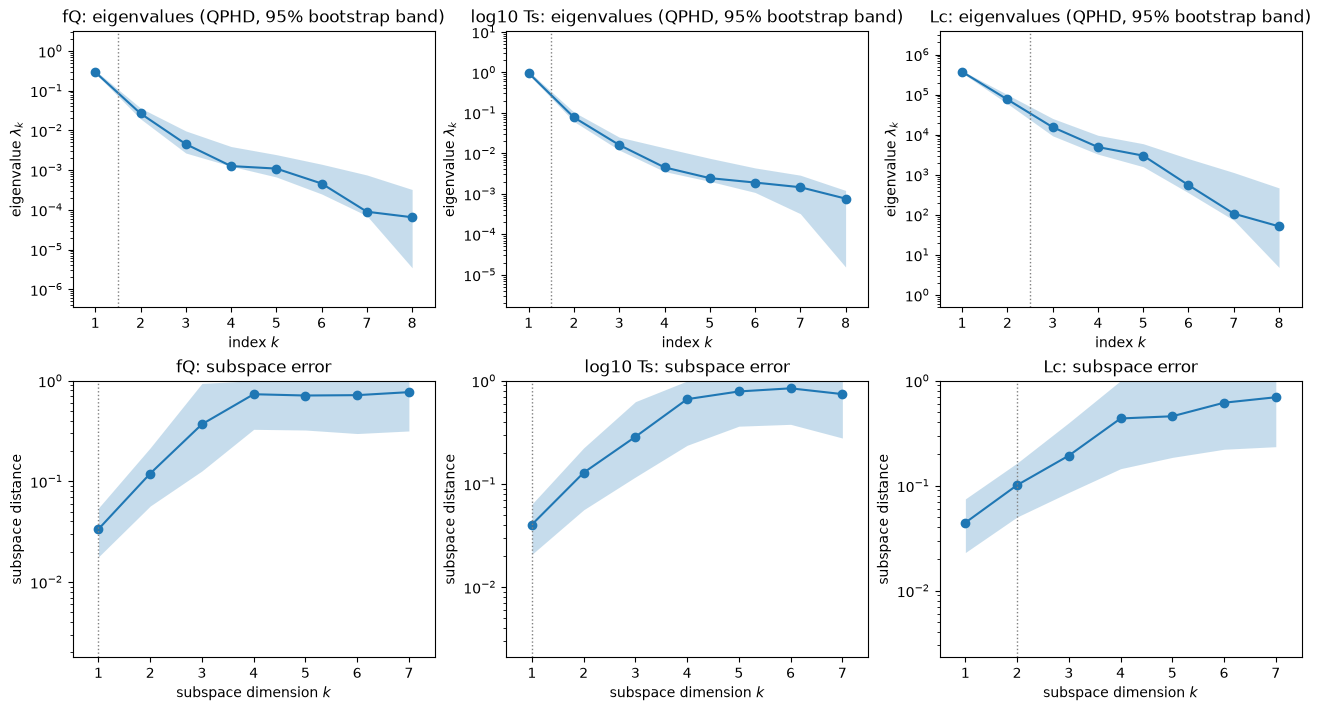

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for j, q in enumerate(QOI):
    ac.plotting.plot_eigenvalues(SUB[q], ax=axs[0, j])
    axs[0, j].set_title(q + ": eigenvalues (QPHD, 95% bootstrap band)")
    ac.plotting.plot_subspace_errors(SUB[q], ax=axs[1, j])
    axs[1, j].set_title(q + ": subspace error")
plt.close(fig)
fig

The bands of $\lambda_1$ and $\lambda_2$ are separated for all three outputs ($f_Q$: $\lambda_1$ in [0.2747, 0.3238],
$\lambda_2$ in [0.01949, 0.03655]). The subspace error is smallest at $k = 1$ for every output (0.033, 0.04, 0.044) and
grows with $k$; for $L_c$ the two-dimensional subspace is still well determined (0.101). For $k$ = 4 and 5 the mean bootstrap
distances are 0.733 and 0.712 ($f_Q$), 0.662 and 0.786 ($\log_{10} T_s$), 0.436 and 0.458 ($L_c$), on a scale whose
maximum is 1: those directions are poorly determined.

### Eigenvectors

Weights of $\mathbf{w}_1$ and $\mathbf{w}_2$ (QPHD), with the local-linear $\mathbf{w}_1$ and the OLS direction.

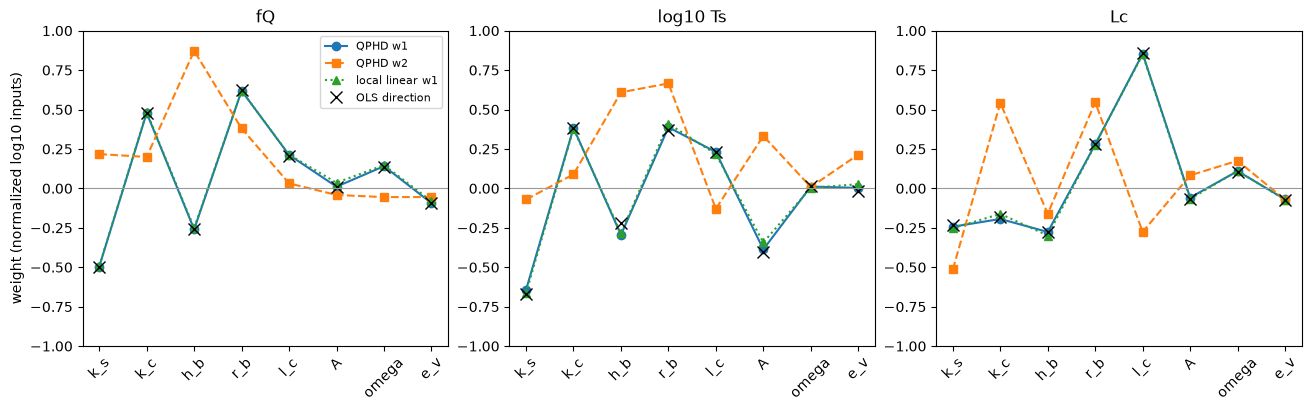

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for j, q in enumerate(QOI):
    qp, ll, ols = R[q]
    x = np.arange(1, 9)
    for k, mk in ((0, "o-"), (1, "s--")):
        axs[j].plot(x, qp.W[:, k], mk, label=f"QPHD w{k + 1}")
    axs[j].plot(x, ll.W[:, 0], "^:", label="local linear w1")
    axs[j].plot(x, ols.W[:, 0], "x", ms=9, color="k", label="OLS direction")
    axs[j].axhline(0, color="0.6", lw=0.8)
    axs[j].set_xticks(x, NAMES, rotation=45)
    axs[j].set_ylim(-1, 1)
    axs[j].set_title(q)
axs[0].set_ylabel("weight (normalized log10 inputs)")
axs[0].legend(fontsize=8)
plt.close(fig)
fig

In [9]:
for q in QOI:
    qp = R[q][0]
    print(q)
    for k in range(2):
        print(f"  w{k + 1}:", "  ".join(f"{nm} {v:+.3f}" for nm, v in zip(NAMES, qp.W[:, k])))
print(f"|cosine| between w2 of Lc and w1 of fQ: {abs(R['Lc'][0].W[:, 1] @ R['fQ'][0].W[:, 0]):.3f}")

fQ
  w1: k_s -0.497  k_c +0.479  h_b -0.260  r_b +0.619  l_c +0.212  A +0.011  omega +0.141  e_v -0.093
  w2: k_s +0.217  k_c +0.199  h_b +0.872  r_b +0.380  l_c +0.032  A -0.042  omega -0.055  e_v -0.055
log10 Ts
  w1: k_s -0.643  k_c +0.383  h_b -0.294  r_b +0.387  l_c +0.231  A -0.387  omega +0.012  e_v +0.003
  w2: k_s -0.070  k_c +0.089  h_b +0.609  r_b +0.666  l_c -0.129  A +0.332  omega +0.009  e_v +0.214
Lc
  w1: k_s -0.243  k_c -0.194  h_b -0.276  r_b +0.279  l_c +0.854  A -0.058  omega +0.110  e_v -0.069
  w2: k_s -0.513  k_c +0.542  h_b -0.161  r_b +0.546  l_c -0.276  A +0.083  omega +0.175  e_v -0.072
|cosine| between w2 of Lc and w1 of fQ: 0.868


$f_Q$ rises along $\mathbf{w}_1$ with $r_b$ (+0.619) and $k_c$ (+0.479) and falls with $k_s$ (−0.497) and $h_b$
(−0.260); $A$ (+0.011) has no weight. A larger aspect ratio slows cavity opening by sliding (Eq. A2), a larger
channel conductivity favours channels, and a larger sheet conductivity favours the sheet; the paper reads the
sensitivity to $r_b$ the same way (p. 4060). $\mathbf{w}_2$ of $f_Q$ is mostly $h_b$ (+0.872).
$\log_{10} T_s$ falls along $\mathbf{w}_1$ with $k_s$ (−0.643), the largest weight, as the paper notes for the
sensitivity indices (p. 4060), and with $A$ (−0.387); it rises with $r_b$ (+0.387) and $k_c$ (+0.383).
$L_c$'s $\mathbf{w}_1$ is dominated by $l_c$ (+0.854), the width of sheet beneath a channel whose flow adds to channel
melt (Eq. A7); the paper reads $l_c$ as the control of channel initiation (p. 4060). Its $\mathbf{w}_2$ ($k_c$ +0.542, $r_b$ +0.546, $k_s$ −0.513)
has |cosine| 0.868 with $\mathbf{w}_1$ of $f_Q$: the second direction of channel length is the channelization
direction of the discharge fraction. The transition parameter $\omega$ and the void fraction $e_v$ have weights of at
most 0.141 in absolute value in the three $\mathbf{w}_1$.

### Sufficient summary plots

Training runs (circles) and test runs (triangles) against $y_1 = \mathbf{w}_1^\top\mathbf{x}$; the right panel
shows the training runs of $L_c$ on the two active variables, coloured by $L_c$.

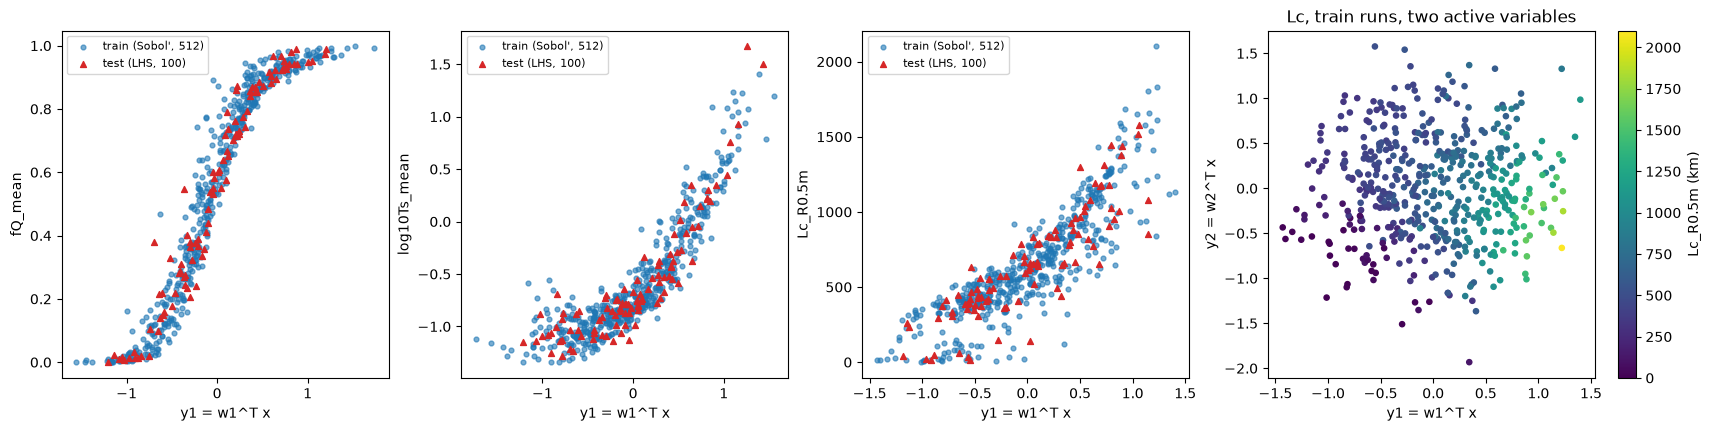

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(17, 4.2), constrained_layout=True)
for j, q in enumerate(["fQ", "log10 Ts", "Lc"]):
    c = QOI[q]
    W1 = SUB[q].W[:, 0]
    axs[j].scatter(space.to_normalized(Ltr) @ W1, Ytr[:, col[c]], s=12, alpha=0.6, label="train (Sobol', 512)")
    axs[j].scatter(space.to_normalized(Lte) @ W1, Yte[:, col[c]], s=18, marker="^", color="C3", label="test (LHS, 100)")
    axs[j].set_xlabel("y1 = w1^T x")
    axs[j].set_ylabel(c)
    axs[j].legend(fontsize=8)
Y2 = space.to_normalized(Ltr) @ SUB["Lc"].W[:, :2]
sc = axs[3].scatter(Y2[:, 0], Y2[:, 1], c=Ytr[:, col["Lc_R0.5m"]], s=14, cmap="viridis")
fig.colorbar(sc, ax=axs[3], label="Lc_R0.5m (km)")
axs[3].set_xlabel("y1 = w1^T x")
axs[3].set_ylabel("y2 = w2^T x")
axs[3].set_title("Lc, train runs, two active variables")
plt.close(fig)
fig

$f_Q$ is a sigmoid of $y_1$, from near 0 to near 1, and the test runs, which were not used in the fit, lie on the
same curve. $\log_{10} T_s$ is flat for negative $y_1$ and rises steeply for positive $y_1$; the scatter in the flat
part is the structure left to other directions (test $R^2$ of one variable 0.911). $L_c$ grows with $y_1$ in a
wide band, and a group of runs with small $L_c$ at negative $y_1$ lies below it. In the two-variable panel the colour
also changes across the band along $y_2$; that is the variation the second variable captures (test $R^2$ 0.764 with
one variable, 0.919 with two).

## Comparison with the paper

The paper gives no active subspace. It gives first-order and total Sobol' indices of GP emulators fitted to
256 training runs (p. 4058; the first 256 rows, per the authors' `sensitivity_indices.py`), computed from 5120
emulator evaluations (p. 4059; Fig. 12, p. 4061; bars only, no values printed). The activity score $\alpha_i(n) = \sum_{j \le n} \lambda_j w_{ij}^2$ is a different measure (the
mean squared derivative along the active directions), so only the order of the inputs is compared, as shares
$\alpha_i / \sum_k \alpha_k$. Fig. 12 is labelled $f_Q$ and $\log T_s$, which the text (p. 4053) defines as gate means, but the authors'
script for Fig. 12 (`experiments/synthetic/analysis/sensitivity_indices.py`, `cols = [5, 5, 0]`) reads the 30 km
gate of $f_Q$ and $\log_{10} T_s$; both are shown. To compare sizes as well as order, the bars are also divided by
their sum (`S_T / sum`), and for $f_Q$ and $\log_{10} T_s$, whose chosen n is 1, the shares with n = 2 are added.

In [11]:
GATE = {"fQ": "fQ_x30km", "log10 Ts": "log10Ts_x30km"}  # the columns the authors' Fig. 12 script reads
FIG12_ST = {  # total indices read from the bars of Fig. 12, p. 4061 (no values printed; read to about 0.03)
    "fQ": [0.34, 0.29, 0.14, 0.40, 0.06, 0.00, 0.01, 0.01],
    "log10 Ts": [0.55, 0.17, 0.13, 0.21, 0.04, 0.14, 0.00, 0.00],
    "Lc": [0.13, 0.13, 0.11, 0.15, 0.64, 0.01, 0.02, 0.01],
}


def shares_of(sub, n):
    a = ac.activity_scores(sub, n=n)
    return a / a.sum()


for q in QOI:
    n = N_CHOSEN[q]
    st = np.array(FIG12_ST[q])
    top5 = np.argsort(-st, kind="stable")[:5]  # the five largest bars
    shares = {f"{QOI[q]}, n={n}": shares_of(SUB[q], n)}
    if n == 1:
        shares[f"{QOI[q]}, n=2"] = shares_of(R[q][0], 2)
    if q in GATE:
        g = ac.active_subspace(space=space, X=Ltr, f=Ytr[:, col[GATE[q]]], estimator="qphd", n=n, qoi=GATE[q])
        lam = np.abs(g.eigenvalues)
        shares[f"{GATE[q]}, n={n}"] = shares_of(g, n)
        print(f"--- {q}; {GATE[q]}: QPHD ratios {np.round(lam[:3] / lam[1:4], 2)}, "
              f"distance between its w1 and that of {QOI[q]}: {dist(g.W[:, :n], SUB[q].W[:, :n]):.3f}")
    else:
        print(f"--- {q}")
    print(f"  {'input':6s} {'Fig. 12 S_T':>11s} {'S_T / sum':>10s}" + "".join(f"{'share, ' + k:>26s}" for k in shares))
    for i, nm in enumerate(NAMES):
        print(f"  {nm:6s} {st[i]:11.2f} {st[i] / st.sum():10.3f}" + "".join(f"{v[i]:26.3f}" for v in shares.values()))
    print("  Spearman rank correlation with Fig. 12, all 8 inputs: "
          + ", ".join(f"{spearmanr(st, v)[0]:.2f} ({k})" for k, v in shares.items()))
    print("  the same over the five largest bars: "
          + ", ".join(f"{spearmanr(st[top5], v[top5])[0]:.2f} ({k})" for k, v in shares.items()))

--- fQ; fQ_x30km: QPHD ratios [9.85 7.87 1.9 ], distance between its w1 and that of fQ_mean: 0.090
  input  Fig. 12 S_T  S_T / sum       share, fQ_mean, n=1       share, fQ_mean, n=2      share, fQ_x30km, n=1
  k_s           0.34      0.272                     0.247                     0.230                     0.296
  k_c           0.29      0.232                     0.229                     0.213                     0.217
  h_b           0.14      0.112                     0.067                     0.125                     0.082
  r_b           0.40      0.320                     0.383                     0.363                     0.345
  l_c           0.06      0.048                     0.045                     0.041                     0.039
  A             0.00      0.000                     0.000                     0.000                     0.001
  omega         0.01      0.008                     0.020                     0.018                     0.010
  e_v           0.01 

The input with the largest total index in Fig. 12 has the largest activity share for every output: $r_b$ for
$f_Q$ (share 0.383), $k_s$ for $\log_{10} T_s$ (0.414), $l_c$ for $L_c$ (0.618). Over all eight inputs the rank
correlations with the bars read from the figure are 0.97–0.99, and they hold for the 30 km gate columns too, whose
$\mathbf{w}_1$ lies at distance 0.090 and 0.103 from that of the gate means. These correlations are raised by the
inputs with near-zero bars ($A$, $\omega$, $e_v$ for $f_Q$), whose order the figure does not resolve; over the five
largest bars they are 1.00 ($f_Q$), 0.90 ($\log_{10} T_s$, where $r_b$, $k_c$ and $A$ have nearly equal shares, 0.150, 0.147 and 0.150) and 0.97
($L_c$). The paper's remark that $\omega$ has very weak influence on all outputs (p. 4060) holds here: its share is
at most 0.020.

The main difference with n = 1 is in size: for $f_Q$, $h_b$ has 0.112 of the summed total indices but an activity
share of 0.067. $h_b$ acts mostly along $\mathbf{w}_2$, which the n = 1 score leaves out. With n = 2 its share is
0.125, and the four largest shares ($k_s$ 0.230, $k_c$ 0.213, $h_b$ 0.125, $r_b$ 0.363) are close to the normalized
bars (0.272, 0.232, 0.112, 0.320). Sobol' total indices also include interactions, which activity scores do not
separate, so close agreement in size is not expected.

Table 5 (p. 4059) gives the test RMSE of the paper's GP emulators (256 training runs, all eight inputs). The same
error for RBF surrogates on n active variables, fitted to the first 256 and to all 512 training runs:

In [12]:
TABLE5 = {"fQ": 0.034, "log10 Ts": 0.097, "Lc": 90.0}  # GP test RMSE, 256 training runs, Table 5, p. 4059
for q, c in QOI.items():
    f, ft = Ytr[:, col[c]], Yte[:, col[c]]
    print(f"{q}: Table 5 GP test RMSE {TABLE5[q]:g}; RBF surrogate on n active variables, test RMSE:")
    for M in (256, 512):
        row = []
        for n in (1, 2, 3):
            sub = ac.active_subspace(space=space, X=Ltr[:M], f=f[:M], estimator="qphd", n=n, qoi=c)
            s = ac.fit_surrogate(X=Ltr[:M], f=f[:M], subspace=sub, kind="rbf")
            row.append(f"n = {n}: {np.sqrt(np.mean((ac.predict(s, Lte) - ft) ** 2)):.3g}")
        print(f"  first {M} runs: " + ", ".join(row))

fQ: Table 5 GP test RMSE 0.034; RBF surrogate on n active variables, test RMSE:


  first 256 runs: n = 1: 0.0686, n = 2: 0.0436, n = 3: 0.0425


  first 512 runs: n = 1: 0.0654, n = 2: 0.0349, n = 3: 0.0295
log10 Ts: Table 5 GP test RMSE 0.097; RBF surrogate on n active variables, test RMSE:


  first 256 runs: n = 1: 0.168, n = 2: 0.133, n = 3: 0.113


  first 512 runs: n = 1: 0.166, n = 2: 0.134, n = 3: 0.111
Lc: Table 5 GP test RMSE 90; RBF surrogate on n active variables, test RMSE:


  first 256 runs: n = 1: 173, n = 2: 105, n = 3: 103


  first 512 runs: n = 1: 173, n = 2: 101, n = 3: 89.5


With the first 256 runs, one active variable gives test RMSE 0.0686 for $f_Q$ (GP: 0.034) and 0.168 for
$\log_{10} T_s$ (GP: 0.097), and two give 105 km for $L_c$ (GP: 90 km). The active-variable surrogates approach the GP only
with more variables or runs (512 runs: 0.0349 for $f_Q$ with n = 2, 89.5 km for $L_c$ with n = 3): the chosen
subspaces summarize most of the variation, and the rest is spread over directions that a low-dimensional surrogate
ignores.

| quantity | paper (page) | this notebook |
|---|---|---|
| inputs, ranges | 8 parameters, Table 2 (p. 4047), log-transformed (p. 4052) | 8 inputs, log-uniform on the Table 2 ranges |
| training design | 512 Sobol' points (p. 4052) | scrambled Sobol' of the authors' `train_config.py` (scipy, seed 20240318) reproduces the log10 design to 2.1e-07; each log10 input fills all 512 strata |
| test design | 100-point centred-discrepancy-minimised LHS (p. 4052) | 100 runs at the centres of 100 strata per input |
| test parameter values, Table B1 (p. 4067) | simulations 66, 63, 71 | run_id 67, 64, 72: 23 of 24 values agree to two digits; for simulation 63 Table B1 prints $\omega = 1.3 \times 10^{-4}$, outside the Table 2 range, and the file has $1.3 \times 10^{-3}$ (apparent misprint) |
| test range $f_Q$, $\log T_s$, $L_c$ (Table 5) | [0.0015, 0.99], [−1.28, 1.67], [16, 1581] km | [0.0015, 0.9901], [−1.279, 1.669], [15.85, 1581] km |
| test RMSE, 256 runs (Table 5) | GP: 0.034, 0.097, 90 km | RBF on n = 1, 1, 2: 0.0686, 0.168, 105 km |
| MAPE (Table 5) | 5.2 %, 8.8 %, 9.0 % | not computed |
| largest total Sobol' index (Fig. 12, p. 4061) | $r_b$ (about 0.40), $k_s$ (about 0.55), $l_c$ (about 0.64) | largest activity share: $r_b$ 0.383, $k_s$ 0.414, $l_c$ 0.618 |
| $h_b$ for $f_Q$, share of the summed bars (Fig. 12) | about 0.112 | activity share 0.067 (n = 1), 0.125 (n = 2) |
| influence of $\omega$ (p. 4060) | "very weak" | activity share at most 0.020 |
| active subspace | not reported | n = 1, 1, 2 (LOO $R^2$ rule); $\lambda_1/\lambda_2$ = 10.97, 12.43, 4.9 |

## References

- T. Hill, D. Bingham, G. E. Flowers, M. J. Hoffman, Computationally efficient subglacial drainage modelling using
  Gaussian process emulators: GlaDS-GP v1.0, *Geosci. Model Dev.* 18, 4045–4074 (2025),
  [doi:10.5194/gmd-18-4045-2025](https://doi.org/10.5194/gmd-18-4045-2025).
- T. Hill, D. Bingham, G. Flowers, M. Hoffman, timghill/GladsGP: v1.0.0, Zenodo (2025),
  [doi:10.5281/zenodo.15053542](https://doi.org/10.5281/zenodo.15053542) (the runs used here; MIT licence).
- M. A. Werder, I. J. Hewitt, C. G. Schoof, G. E. Flowers, Modeling channelized and distributed subglacial drainage
  in two dimensions, *J. Geophys. Res. Earth Surf.* 118, 2140–2158 (2013),
  [doi:10.1002/jgrf.20146](https://doi.org/10.1002/jgrf.20146).
- T. Hill, G. E. Flowers, M. J. Hoffman, D. Bingham, M. A. Werder, Improved representation of laminar and turbulent
  sheet flow in subglacial drainage models, *J. Glaciol.* 70, e24 (2024),
  [doi:10.1017/jog.2023.103](https://doi.org/10.1017/jog.2023.103).
- E. Larour, H. Seroussi, M. Morlighem, E. Rignot, Continental scale, high order, high spatial resolution, ice sheet
  modeling using the Ice Sheet System Model (ISSM), *J. Geophys. Res. Earth Surf.* 117, F01022 (2012),
  [doi:10.1029/2011JF002140](https://doi.org/10.1029/2011JF002140).
- B. de Fleurian et al., SHMIP: The subglacial hydrology model intercomparison Project, *J. Glaciol.* 64, 897–916
  (2018), [doi:10.1017/jog.2018.78](https://doi.org/10.1017/jog.2018.78).
- P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM (2015),
  [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).
- K.-C. Li, On principal Hessian directions for data visualization and dimension reduction: another application
  of Stein's lemma, *J. Amer. Statist. Assoc.* 87(420), 1025–1039 (1992),
  [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258).

## Acknowledgments

From the paper (p. 4070): T. Hill was supported by Simon Fraser University and the NSERC Canada Graduate
Scholarship programme, G. E. Flowers and D. Bingham by NSERC Discovery Grants. Financial support: NSERC (grant
no. RGPIN-2020-05025) and the U.S. Department of Energy, Office of Science, Office of Biological and Environmental
Research and Office of Advanced Scientific Computing Research, under Triad National Security, LLC contract
89233218CNA000001 (FWP LANLF2C2). Computing was provided by WestDRI, Calcul Québec and the Digital Research
Alliance of Canada.

In [13]:
print(f"notebook run time {time.perf_counter() - t_start:.0f} s")

notebook run time 22 s
